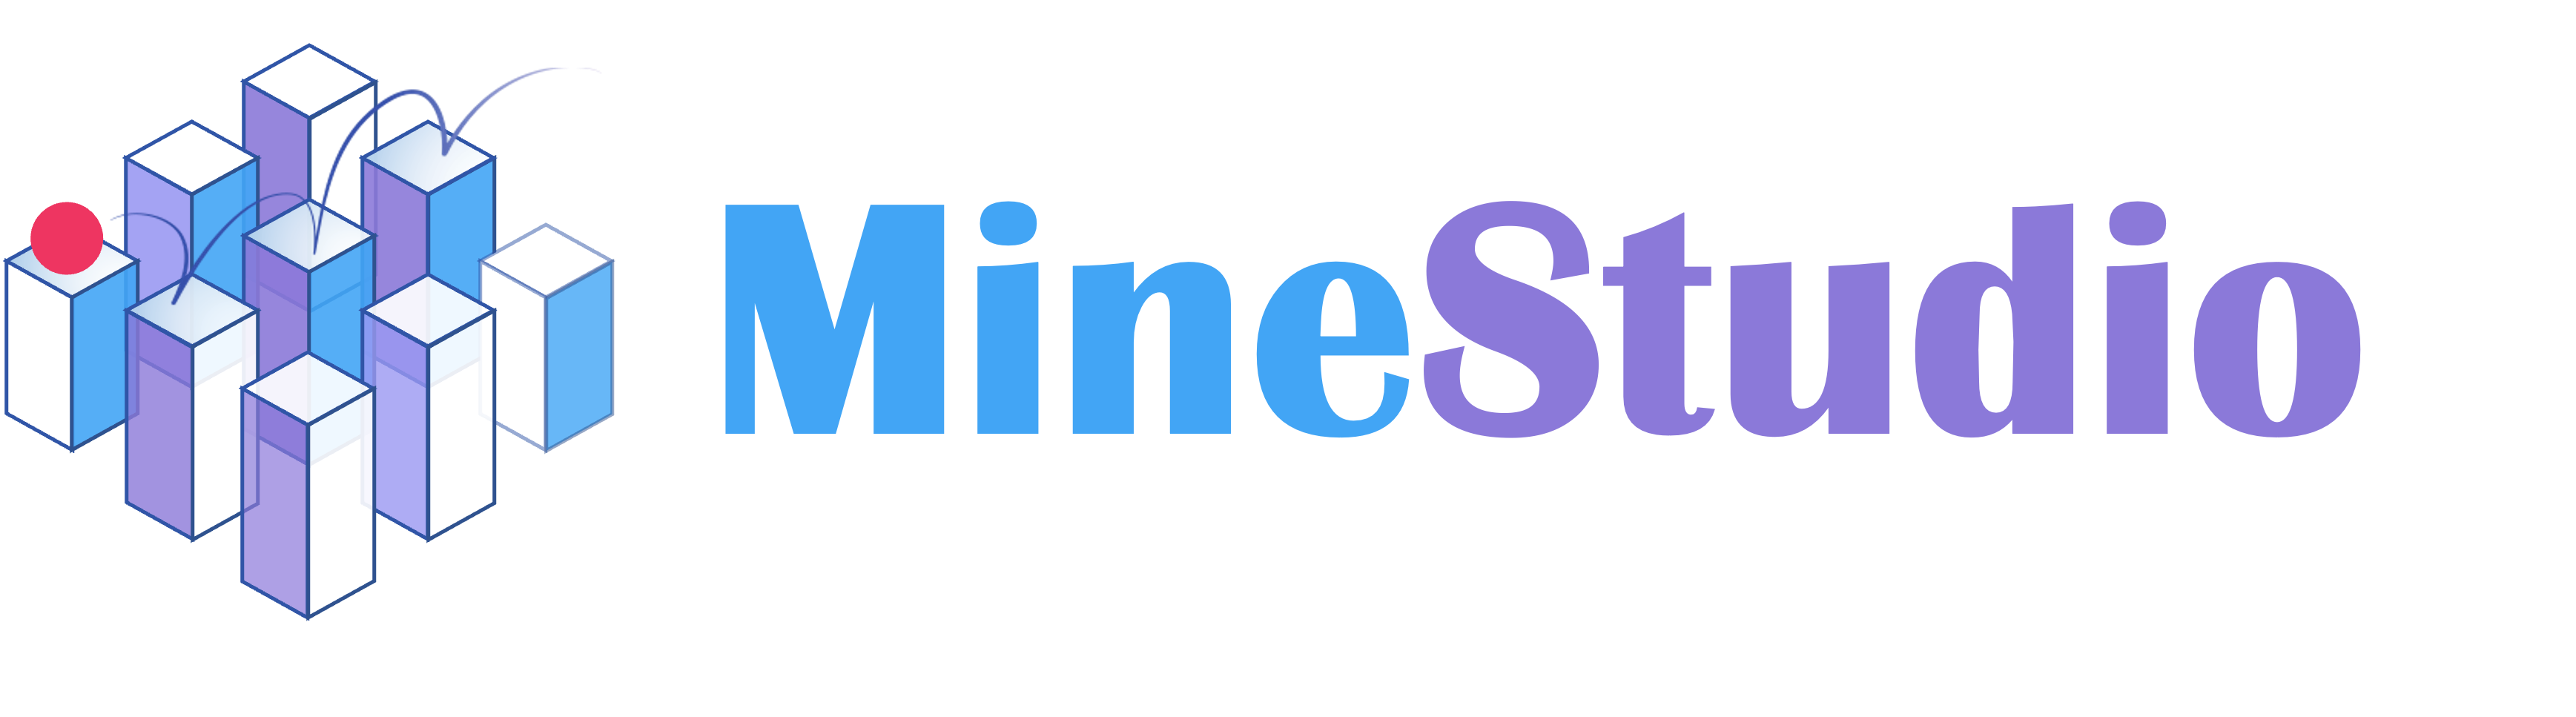

https://craftjarvis.github.io/MineStudio/overview/getting-started.html

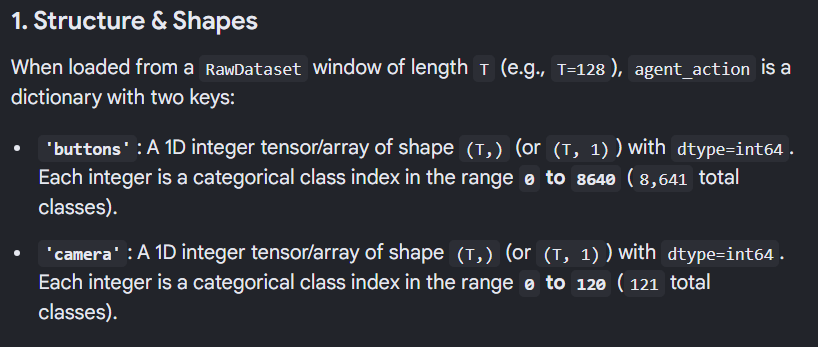
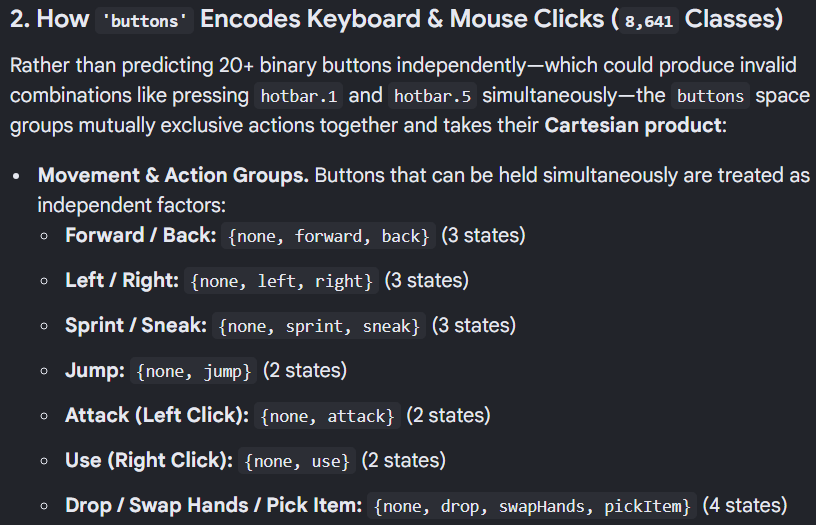
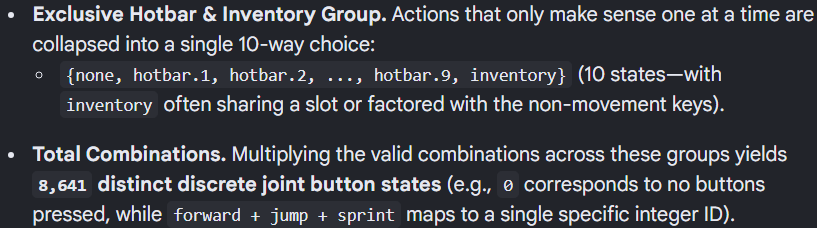
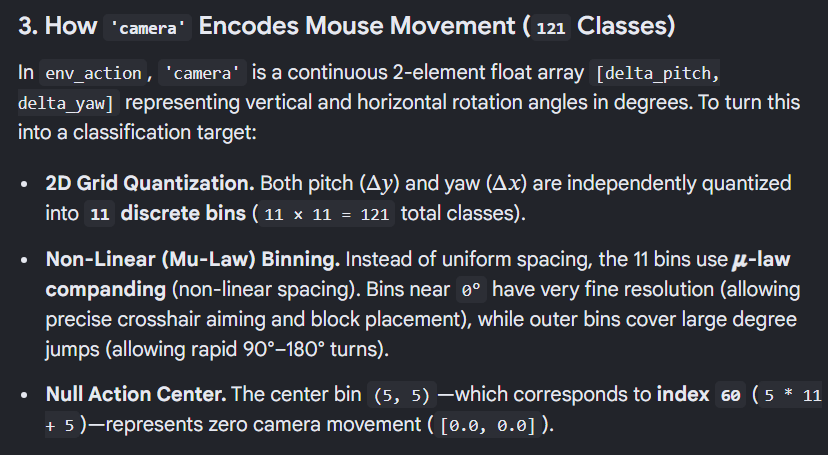

Another promising dataset: **MineRL BASALT 2022 Dataset**

In [1]:
from dotenv import load_dotenv

load_dotenv()  # Reads the .env file and sets HF_TOKEN in os.environ

True

In [2]:
import minestudio

In [ ]:
from minestudio.data import RawDataset
from minestudio.data.minecraft.callbacks import ImageKernelCallback, ActionKernelCallback

dataset = RawDataset(
    dataset_dirs=[
        #'6xx', 
        #'7xx', 
        #'8xx', 
        #'9xx', 
        #'10xx', 
    ],
    modal_kernel_callbacks=[
        ImageKernelCallback(frame_width=224, frame_height=224, enable_video_aug=False), 
        ActionKernelCallback(enable_prev_action=True, win_bias=1, read_bias=-1),
    ],
    win_len=128, 
    split_ratio=0.9,
    shuffle_episodes=True,
)
item = dataset[0]
print(item.keys())

Download Dataset
        Dataset: 6xx
        Base Dir: /tmp/MineStudio
        Total Size: 219.28 GB
        Free Space: 912.29 GB

Fetching 76 files:  62%|██████▏   | 47/76 [00:40<00:08,  3.29it/s]

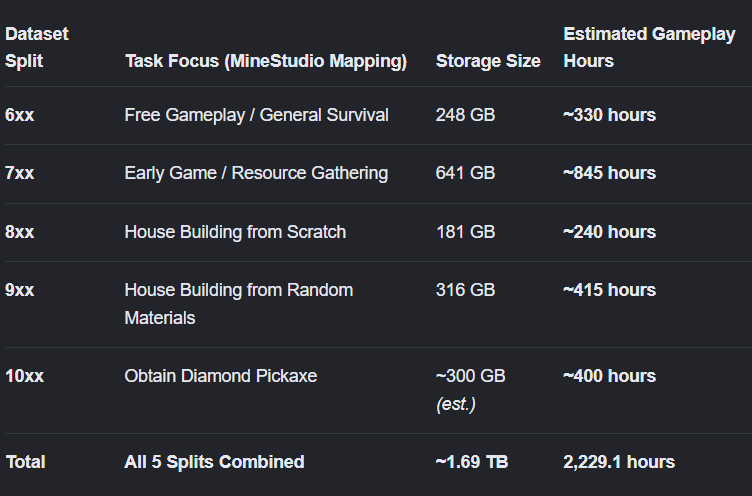

This is a lot. Let's download like 5% of 6xx (=12.4GB) to test out the architecture. Then donwload 10% of all (=179GB) to create the first mid scale version. Then train on the full data using a cloud prov.

6xx: https://huggingface.co/datasets/CraftJarvis/minestudio-data-6xx-v110

In [2]:
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="CraftJarvis/minestudio-data-6xx-v110",
    repo_type="dataset",
    allow_patterns=["*1900*", "*.json", "*.yaml"],
    local_dir="../data/minestudio_6xx_1900"
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

'/workspaces/MineBot/data/minestudio_6xx_1900'

In [ ]:
from minestudio.data import RawDataset
from minestudio.data.minecraft.callbacks import ImageKernelCallback, ActionKernelCallback

dataset = RawDataset(
    dataset_dirs=[
        "../data/minestudio_6xx_1900" 
    ],
    modal_kernel_callbacks=[
        ImageKernelCallback(frame_width=224, frame_height=224, enable_video_aug=False), 
        ActionKernelCallback(enable_prev_action=True, win_bias=1, read_bias=-1),
    ],
    seed=42,
    win_len=128, 
    split='train',
    split_ratio=0.8,
    shuffle_episodes=True,
)
item = dataset[0]
print(item.keys())

[20:31:39] [Kernel] Modal image load 464 episodes.                                                      ]8;id=4111085;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py\core.py]8;;\:]8;id=4111086;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py#157\157]8;;\

[20:31:39] [Kernel] Modal action load 920 episodes.                                                     ]8;id=4111091;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py\core.py]8;;\:]8;id=4111092;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py#157\157]8;;\

[20:31:39] [Kernel] episodes: 158, frames: 1173888.                                                     ]8;id=4111098;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py\core.py]8;;\:]8;id=4111099;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py#170\170]8;;\

[Raw Dataset] Shuffling episodes with seed 0.

dict_keys(['image', 'image_mask', 'action_mask', 'env_action', 'env_prev_action', 'agent_action', 'agent_prev_action', 'mask', 'text', 'timestamp', 'episode', 'progress'])


In [7]:
item['image'].shape

torch.Size([128, 224, 224, 3])

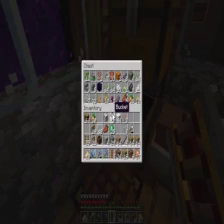

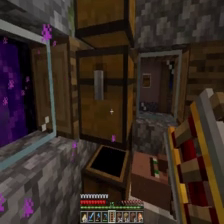

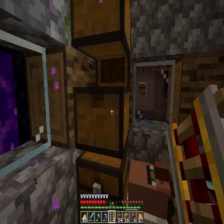

In [22]:
import torch
from torchvision.transforms.functional import to_pil_image

for i in range(0, 15, 5):
    img = to_pil_image(
        item['image'][i].permute(2, 0, 1)
    )
    img.show()

In [29]:
for key in item.keys():
    if key not in ['image', 'image_mask']:
        print("key: " + key, type(item[key]), item[key].shape if type(item[key]) == torch.Tensor else "")

key: action_mask <class 'torch.Tensor'> torch.Size([128])
key: env_action <class 'dict'> 
key: env_prev_action <class 'dict'> 
key: agent_action <class 'dict'> 
key: agent_prev_action <class 'dict'> 
key: mask <class 'torch.Tensor'> torch.Size([128])
key: text <class 'str'> 
key: timestamp <class 'torch.Tensor'> torch.Size([128])
key: episode <class 'str'> 
key: progress <class 'str'> 


# Dataset & Dataloader

In [1]:
from minestudio.data import RawDataset
from minestudio.data.minecraft.callbacks import ImageKernelCallback, ActionKernelCallback

dataset = RawDataset(
    dataset_dirs=[
        "../data/minestudio_6xx_1900" 
    ],
    modal_kernel_callbacks=[
        ImageKernelCallback(frame_width=224, frame_height=224, enable_video_aug=False), 
        ActionKernelCallback(enable_prev_action=True, win_bias=1, read_bias=-1),
    ],
    seed=42,
    win_len=128, 
    split='train',
    split_ratio=0.8,
    shuffle_episodes=True,
)
item = dataset[0]
print(item.keys())

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


[21:43:45] [Kernel] Modal image load 464 episodes.                                                      ]8;id=2231407;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py\core.py]8;;\:]8;id=2231408;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py#157\157]8;;\

[21:43:45] [Kernel] Modal action load 920 episodes.                                                     ]8;id=2231413;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py\core.py]8;;\:]8;id=2231414;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py#157\157]8;;\

[21:43:45] [Kernel] episodes: 158, frames: 1173888.                                                     ]8;id=2231420;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py\core.py]8;;\:]8;id=2231421;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py#170\170]8;;\

[Raw Dataset] Shuffling episodes with seed 42.

dict_keys(['image', 'image_mask', 'action_mask', 'env_action', 'env_prev_action', 'agent_action', 'agent_prev_action', 'mask', 'text', 'timestamp', 'episode', 'progress'])


In [1]:
from minestudio.data import RawDataset
from minestudio.data.minecraft.callbacks import ImageKernelCallback, ActionKernelCallback

import torch
from torch.utils.data import Dataset

class MineBotDataset(Dataset):
    def __init__(self, 
                 dataset_dirs: list[str],
                 frame_width: int,
                 frame_height: int,
                 window_len: int=128,
                 seed: int = 42
                ):
        super().__init__()

        self.dataset = RawDataset(
            dataset_dirs=dataset_dirs,
            modal_kernel_callbacks=[
                ImageKernelCallback(frame_width=frame_width, frame_height=frame_height, enable_video_aug=False), 
                ActionKernelCallback(enable_prev_action=False, win_bias=1, read_bias=-1),
            ],
            seed=seed,
            win_len=window_len, 
            split='train',
            split_ratio=1.0,
            shuffle_episodes=True,
        )

        self.frame_width = frame_width
        self.frame_height = frame_width

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        return self.dataset[index]

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [2]:
from torch.utils.data import DataLoader, random_split

dataset = MineBotDataset(dataset_dirs=["../data/minestudio_6xx_1900"], frame_width= 224, frame_height=224)

generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset, test_dataset = random_split(
    dataset, [0.7, 0.15, 0.15], generator=generator
)

# 3. Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)


[21:59:17] [Kernel] Modal image load 464 episodes.                                                      ]8;id=12149064;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py\core.py]8;;\:]8;id=12149065;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py#157\157]8;;\

[21:59:17] [Kernel] Modal action load 920 episodes.                                                     ]8;id=12149070;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py\core.py]8;;\:]8;id=12149071;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py#157\157]8;;\

[21:59:17] [Kernel] episodes: 158, frames: 1173888.                                                     ]8;id=12149077;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py\core.py]8;;\:]8;id=12149078;file:///workspaces/MineBot/.venv/lib/python3.12/site-packages/minestudio/data/minecraft/core.py#170\170]8;;\

[Raw Dataset] Shuffling episodes with seed 42.

In [5]:
train_dataset[0].keys()

dict_keys(['image', 'image_mask', 'action_mask', 'env_action', 'agent_action', 'mask', 'text', 'timestamp', 'episode', 'progress'])

In [9]:
train_dataset[0]['agent_action']['buttons'].shape

torch.Size([129, 1])

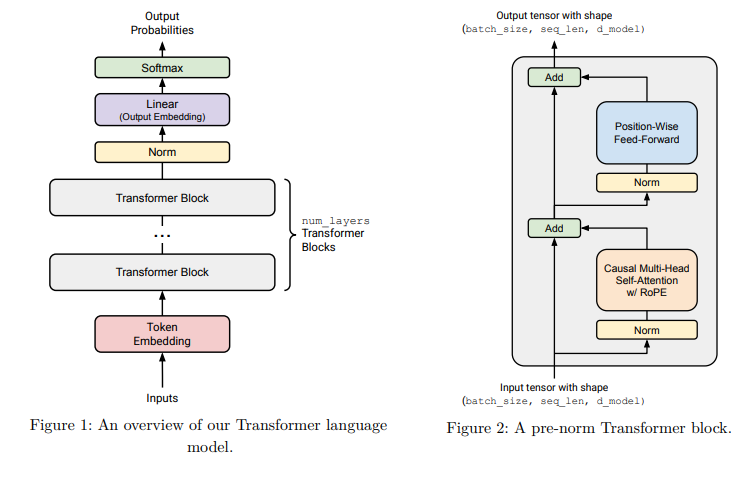

In [ ]:
import torch.nn as nn
from torch.nn.functional import scaled_dot_product_attention

#TODO: implementent using eninops
# The most straight forward case
class MultiHeadSelfAttention(nn.Module):
    def __init__(
            self,
            model_dim: int,
            num_heads: int,
            dropout: float = 0.0,
            bias: bool = False,
            rope: nn.Module | None = None
        ):
        super().__init__()

        assert model_dim % num_heads == 0, "model_dim must be divisible by num_heads"

        self.model_dim = model_dim
        self.num_heads = num_heads
        self.head_dim = model_dim // num_heads
        self.dropout = dropout

        self.qkv_proj = nn.Linear(model_dim, 3 * model_dim, bias=bias)
        self.output_proj = nn.Linear(model_dim, model_dim, bias=bias)

        self.rope = rope

    def forward(self, x: torch.Tensor, mask=None, is_causal: bool = False) -> torch.Tensor:

        batch_size, seq_len, _ = x.shape

        QKV: torch.Tensor = self.qkv_proj(x) # (batch_size, seq_len, model_dim) @ (model_dim, 3 * model_dim) -> (batch_size, seq_len, 3 * model_dim)
        Q, K, V = QKV.chunk(3, dim=-1) # (batch_size, seq_len, 3 * model_dim) -> 3 * (batch_size, seq_len, model_dim)

        # (batch_size, seq_len, model_dim) -> (batch_size, seq_len, self.num_heads, self.head_dim) -> (batch_size, self.num_heads, seq_len, self.head_dim)
        Q = Q.view(batch_size, seq_len, self.num_heads, self.head_dim)
        K = K.view(batch_size, seq_len, self.num_heads, self.head_dim)

        #TODO: need to pass in input_pos
        if self.rope:
            Q = self.rope(Q)
            K = self.rope(K)

        Q = Q.transpose(1, 2)
        K = K.transpose(1, 2)
        
        V = V.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)

        #A = softmax((Q @ K.t)/scale) -> 
        #(batch_size, self.num_heads, seq_len, self.head_dim) @ (batch_size, self.num_heads, self.head_dim, seq_len) ->
        # (batch_size, self.num_heads, seq_len, seq_len)

        # attn_out = A @ V
        # (batch_size, self.num_heads, seq_len, seq_len) @ (batch_size, self.num_heads, seq_len, self.head_dim) ->
        # (batch_size, self.num_heads, seq_len, self.head_dim)
        attn_out = scaled_dot_product_attention(
            Q, K, V,
            attn_mask=mask,
            dropout_p=self.dropout if self.training else 0.0,
            is_causal=is_causal
        )

        #(batch_size, self.num_heads, seq_len, self.head_dim) -> (batch_size, seq_len, self.num_heads, self.head_dim)
        attn_out = attn_out.transpose(1,2).contiguous() #add .contiguous() to make sure the memory is nicely ordered after the transpose

        #recall: self.head_dim = model_dim // num_heads, so:
        # self.model_dim = self.head_sim * num_heads (so view just mutiplies dims 3 and 4)

        #(batch_size, seq_len, self.num_heads, self.head_dim) -> (batch_size, seq_len, self.model_dim)
        attn_out = attn_out.view(batch_size, seq_len, self.model_dim)

        #(batch_size, seq_len, self.model_dim) @ (self.model_dim, self.model_dim) -> (batch_size, seq_len, self.model_dim)
        return self.output_proj(attn_out)

class SwiGLU(nn.Module):
    def __init__(
            self,
            model_dim: int,
            ff_dim: int,
            bias: bool = False
        ):
        super().__init__()

        self.proj_1 = nn.Linear(model_dim, ff_dim, bias=bias)
        self.proj_2 = nn.Linear(ff_dim, model_dim, bias=bias)
        self.proj_3 = nn.Linear(model_dim, ff_dim, bias=bias)

        self.silu = nn.SiLU()

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        return self.proj_2(self.silu(self.proj_1(X)) * self.proj_3(X))

class TransformerBlock(nn.Module):
    def __init__(
            self,
            model_dim: int,
            num_heads: int,
            ff_dim: int,
            dropout:float = 0.0,
            bias: bool = False,
            eps: float = 1e-6,
            rope: nn.Module | None = None

        ):
        super().__init__()

        self.norm1 = nn.RMSNorm(model_dim, eps=eps)

        self.attn = MultiHeadSelfAttention(
            model_dim=model_dim,
            num_heads=num_heads,
            dropout=dropout,
            bias=bias,
            rope=rope
        )

        self.norm2 = nn.RMSNorm(model_dim, eps=eps)

        self.ff = SwiGLU(
            model_dim=model_dim,
            ff_dim=ff_dim,
            bias=bias
        )

    def forward(self, X, mask=None, is_causal: bool = False) -> torch.Tensor:

        #Uses pre norm.
        
        normed_X_1 = self.norm1(X)
        
        attn_out = self.attn(normed_X_1, mask, is_causal)
        
        X = X + attn_out
        
        normed_X_2 = self.norm2(X)

        ff_out = self.ff(normed_X_2)

        X = X + ff_out

        return X

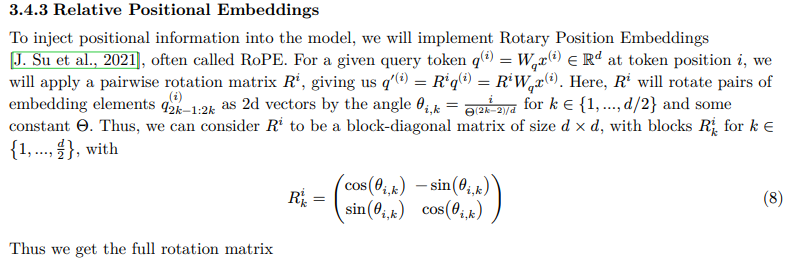
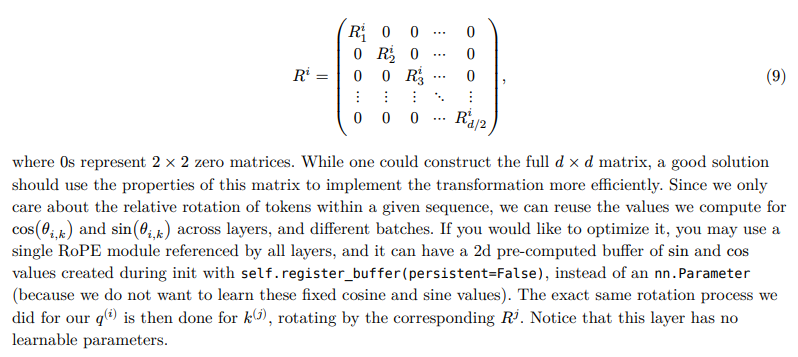

In [ ]:
from typing import Optional

import torch

from torch import nn, Tensor

#TODO: actually understand how this works. I need to get better at working with tensor shapes, generation and manipulation
#TODO: i'm not sure if this implementation will work on AR inference (cached input position is always starting at 0)
class RotaryPositionalEmbeddings(nn.Module):
    """
    This class implements Rotary Positional Embeddings (RoPE)
    proposed in https://arxiv.org/abs/2104.09864.

    Reference implementation (used for correctness verfication)
    can be found here:
    https://github.com/meta-llama/llama/blob/main/llama/model.py#L80

    In this implementation we cache the embeddings for each position upto
    ``max_seq_len`` by computing this during init.

    Args:
        dim (int): Embedding dimension. This is usually set to the dim of each
            head in the attention module computed as ````embed_dim`` // ``num_heads````
        max_seq_len (int): Maximum expected sequence length for the
            model, if exceeded the cached freqs will be recomputed
        base (int): The base for the geometric progression used to compute
            the rotation angles
    """

    def __init__(
        self,
        dim: int,
        max_seq_len: int = 4096,
        base: int = 10_000,
    ) -> None:
        super().__init__()
        assert dim % 2 == 0, "RoPE dimension must be even"
        self.dim = dim
        self.base = base
        self.max_seq_len = max_seq_len
        self._rope_init()

    # We need to explicitly define reset_parameters for FSDP initialization, see
    # https://github.com/pytorch/pytorch/blob/797d4fbdf423dd9320ebe383fb57ffb1135c4a99/torch/distributed/fsdp/_init_utils.py#L885
    def reset_parameters(self):
        self._rope_init()

    def _rope_init(self):
        self.theta = 1.0 / (
            self.base
            ** (torch.arange(0, self.dim, 2)[: (self.dim // 2)].float() / self.dim)
        )
        self.register_buffer("theta", self.theta, persistent=False)
        self.build_rope_cache(self.max_seq_len)

    def build_rope_cache(self, max_seq_len: int = 4096) -> None:
        # Create position indexes `[0, 1, ..., max_seq_len - 1]`
        seq_idx = torch.arange(
            max_seq_len, dtype=self.theta.dtype, device=self.theta.device
        )

        # Outer product of theta and position index; output tensor has
        # a shape of [max_seq_len, dim // 2]
        idx_theta = torch.einsum("i, j -> ij", seq_idx, self.theta).float()

        # cache includes both the cos and sin components and so the output shape is
        # [max_seq_len, dim // 2, 2]
        self.cache = torch.stack([torch.cos(idx_theta), torch.sin(idx_theta)], dim=-1)
        self.register_buffer("cache", self.cache, persistent=False)

    def forward(self, x: Tensor, *, input_pos: Optional[Tensor] = None) -> Tensor:
        """
        Args:
            x (Tensor): input tensor with shape
                [b, s, n_h, h_d]
            input_pos (Optional[Tensor]): Optional tensor which contains the position ids
                of each token. During training, this is used to indicate the positions
                of each token relative to its sample when packed, shape [b, s].
                During inference, this indicates the position of the current token.
                If none, assume the index of the token is its position id. Default is None.

        Returns:
            Tensor: output tensor with RoPE applied

        Notation used for tensor shapes:
            - b: batch size
            - s: sequence length
            - n_h: num heads
            - h_d: head dim

        TODO: The implementation below can be made more efficient
        for inference.
        """
        # input tensor has shape [b, s, n_h, h_d]
        seq_len = x.size(1)

        # extract the values based on whether input_pos is set or not
        rope_cache = (
            self.cache[:seq_len] if input_pos is None else self.cache[input_pos]
        )

        # reshape input; the last dimension is used for computing the output.
        # Cast to float to match the reference implementation
        # tensor has shape [b, s, n_h, h_d // 2, 2]
        xshaped = x.float().reshape(*x.shape[:-1], -1, 2)

        # reshape the cache for broadcasting
        # tensor has shape [b, s, 1, h_d // 2, 2] if packed samples,
        # otherwise has shape [1, s, 1, h_d // 2, 2]
        rope_cache = rope_cache.view(-1, xshaped.size(1), 1, xshaped.size(3), 2)

        # tensor has shape [b, s, n_h, h_d // 2, 2]
        x_out = torch.stack(
            [
                xshaped[..., 0] * rope_cache[..., 0]
                - xshaped[..., 1] * rope_cache[..., 1],
                xshaped[..., 1] * rope_cache[..., 0]
                + xshaped[..., 0] * rope_cache[..., 1],
            ],
            -1,
        )

        # tensor has shape [b, s, n_h, h_d]
        x_out = x_out.flatten(3)
        return x_out.type_as(x)

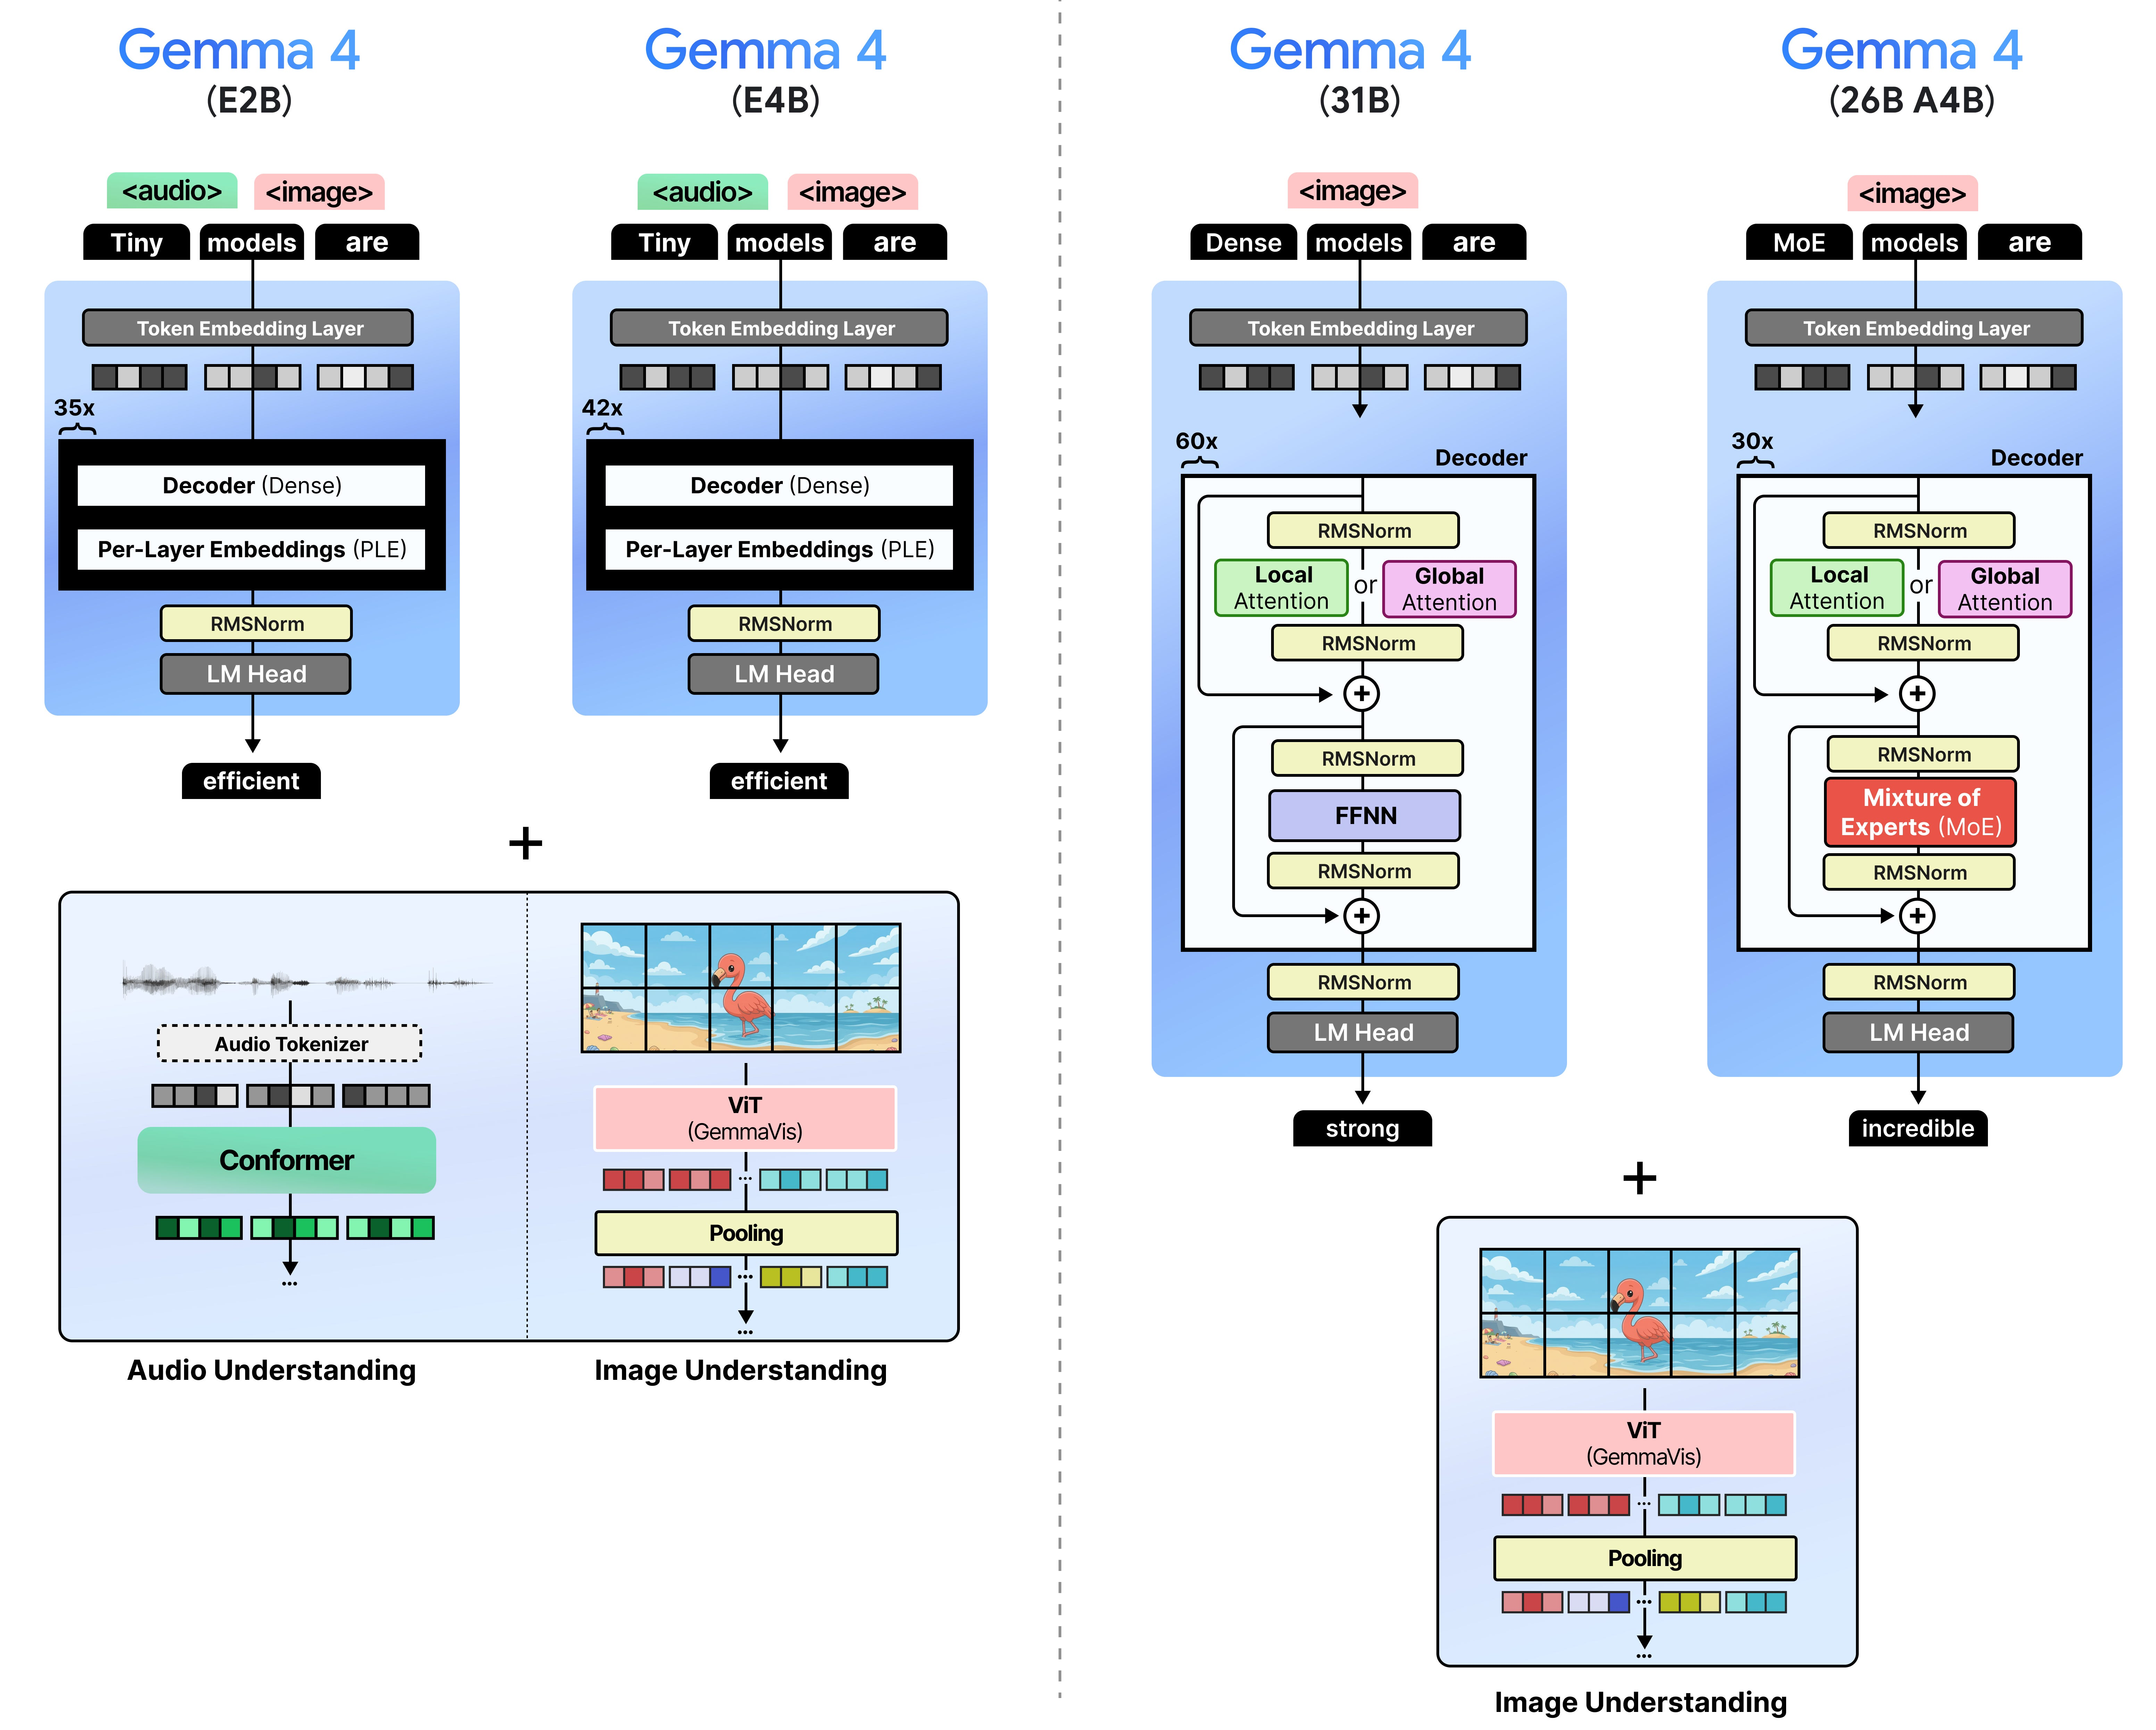

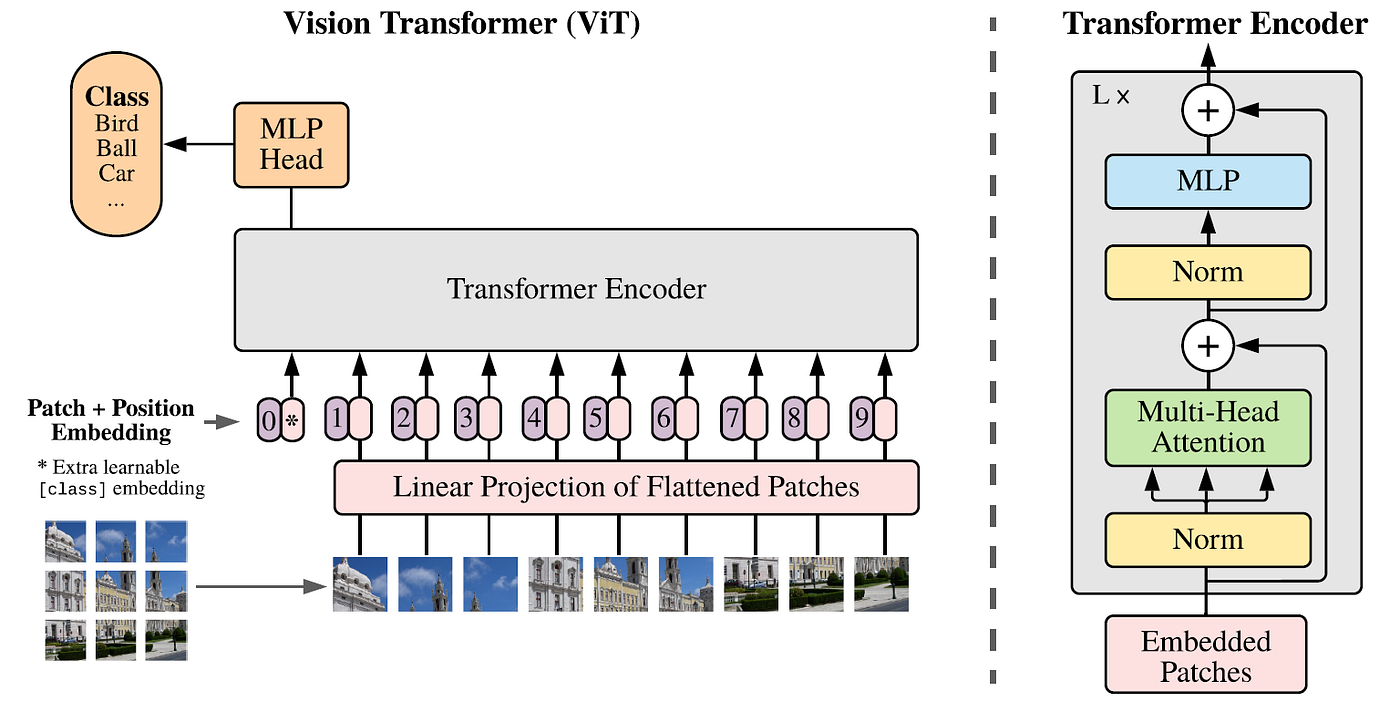

In [ ]:
class FrameEncoder(nn.Module):
    def __init__(
            self,

            num_channels: int,
            patch_size: int,

            model_dim: int,
            output_dim: int,
            num_layers: int,
            num_heads: int,
            ff_dim: int,

            bias: bool = False,
            dropout: float = 0.0,
            eps: float = 1e-6,
        ):

        super().__init__()

        self.cls_token = nn.Parameter(torch.randn(1, 1, model_dim) * 0.02)

        self.patchify_proj = nn.Conv2d(
            in_channels=num_channels,
            out_channels=model_dim,
            kernel_size=patch_size,
            stride=patch_size,
            bias=bias
        )

        self.backbone = nn.Sequential(
            *[TransformerBlock(
                model_dim=model_dim,
                num_heads=num_heads,
                ff_dim=ff_dim,
                dropout=dropout,
                bias=bias,
                eps=eps
            ) for layer in range(num_layers)]
        )

        self.norm = nn.RMSNorm(model_dim, eps=eps)

        #TODO: maybe make this mlp have more layers and an activation if more expression is needed
        self.mlp_head = nn.Linear(
            in_features=model_dim,
            out_features=output_dim,
        )

    def forward(self, x: torch.Tensor):
        # Input shape: (B, C, H, W) -> e.g., (1, 3, 224, 224)
        x = self.patchify_proj(x)        # Output shape: (B, model_dim, H/P, W/P) -> (1, 768, 14, 14)
        x = x.flatten(2)        # Flatten spatial dims: (B, model_dim, num_patches) -> (1, 768, 196)
        x = x.transpose(1, 2)   # Swap dims for Transformer: (B, num_patches, model_dim) -> (1, 196, 768)

        #Batch dim
        B = x.shape[0]

        #Expand (copy) learned cls token into the batch dim
        cls_tokens = self.cls_token.expand(B, -1, -1)

        #Add cls token to seq -> 1 + num_patches
        x = torch.cat((cls_tokens, x), dim=1)

        #Transformer layers (pre norm, SwiGlu, RoPE)
        x = self.backbone(x)

        #RMSnorm
        normed_x = self.norm(x)

        extracted_cls_token = normed_x[:, 0 , :]

        out = self.mlp_head(extracted_cls_token)

        return out

In [ ]:
class ActionEncoder(nn.Module):
    def __init__(
            self,
            output_dim: int,
            num_button_classes: int = 8641,
            num_camera_bins: int = 11,
            dropout: float = 0.0,
        ):
        super().__init__()

        #TODO: try a factored approach, much more efficient

        self.num_camera_bins = num_camera_bins

        self.button_embedding = nn.Embedding(
            num_embeddings=num_button_classes,
            embedding_dim=output_dim,
        )

        self.camera_x_embedding = nn.Embedding(
            num_embeddings=num_camera_bins,
            embedding_dim=output_dim,
        )

        self.camera_y_embedding = nn.Embedding(
            num_embeddings=num_camera_bins,
            embedding_dim=output_dim,
        )

        self.norm = nn.LayerNorm(output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        buttons: torch.Tensor,
        camera: torch.Tensor,
    ) -> torch.Tensor:

        # buttons: (B, T), integer IDs [0, 8640]
        # camera:  (B, T), integer IDs [0, 120]

        camera_x = camera // self.num_camera_bins
        camera_y = camera % self.num_camera_bins

        button_features = self.button_embedding(buttons.long())
        camera_x_features = self.camera_x_embedding(camera_x.long())
        camera_y_features = self.camera_y_embedding(camera_y.long())

        x = (
            button_features
            + camera_x_features
            + camera_y_features
        )

        return self.dropout(self.norm(x))

In [ ]:
"""
import torch
import torch.nn as nn
from minestudio.utils.vpt_lib.action_mapping import CameraHierarchicalMapping


class ActionEncoder(nn.Module):
    def __init__(self, model_dim: int):
        super().__init__()

        mapper = CameraHierarchicalMapping(n_camera_bins=11)

        # 8641 button IDs -> 9 categorical group indices
        groups = list(mapper.BUTTONS_GROUPS.values())

        lookup = torch.zeros(8641, len(groups), dtype=torch.long)

        for action_id, combination in mapper.BUTTONS_IDX_TO_COMBINATION.items():
            if combination == "inventory":
                continue

            lookup[action_id] = torch.tensor([
                group.index(choice)
                for group, choice in zip(groups, combination)
            ])

        self.register_buffer("lookup", lookup)

        self.group_embeddings = nn.ModuleList([
            nn.Embedding(len(group), model_dim)
            for group in groups
        ])

        self.inventory_embedding = nn.Embedding(2, model_dim)

        self.camera_x_embedding = nn.Embedding(11, model_dim)
        self.camera_y_embedding = nn.Embedding(11, model_dim)

        self.norm = nn.LayerNorm(model_dim)

    def forward(self, buttons, camera):
        # buttons, camera: (B, T)

        buttons = buttons.long()
        camera = camera.long()

        group_ids = self.lookup[buttons]

        x = sum(
            embedding(group_ids[..., i])
            for i, embedding in enumerate(self.group_embeddings)
        )

        inventory = (buttons == 8640).long()
        x = x + self.inventory_embedding(inventory)

        # Camera is ignored when camera meta-action is off.
        camera_enabled = (group_ids[..., 8] == 1) & (inventory == 0)
        camera = torch.where(camera_enabled, camera, 60)

        camera_x = camera // 11
        camera_y = camera % 11

        x = x + self.camera_x_embedding(camera_x)
        x = x + self.camera_y_embedding(camera_y)

        return self.norm(x)
"""

In [ ]:
class StateEncoder(nn.Module):
    """
    Encodes a frame, and action into a small joint embedding rep.
    """
    def __init__(
            self,
            model_dim: int,
            frame_emb_dim: int,
            action_emb_dim: int,            
            bias: bool = False,
            dropout: float = 0.0            
        ):
        super().__init__()

        self.frame_encoder = FrameEncoder(
            num_channels=3,
            patch_size=16,
            model_dim=model_dim,
            output_dim=frame_emb_dim,
            num_layers=1,
            num_heads=1,
            ff_dim=1,
            bias=bias,
            dropout=dropout
        )

        self.action_encoder = ActionEncoder(
            output_dim=action_emb_dim,
        )


    def forward(self, frame: torch.Tensor, action: tuple[torch.Tensor, torch.Tensor]):

        #(B, 3, 224, 244) -> (B, frame_emb_dim)
        frame_emd = self.frame_encoder(frame)

        buttons, camera = action
        #(B, T, action_emd_dim)
        #TODO: will probably need to add squezee because of the T, we are not working with sequences of actions in this section.
        action_emd = self.action_encoder(buttons, camera)

        #(B, frame_emb_dim + action_emd_dim)
        return torch.cat((frame_emd, action_emd), dim=-1)

In [ ]:
class Predictor(nn.Module):
    def __init__(
            self,
            model_dim: int,
            num_heads: int,
            num_layers: int,
            ff_dim: int,
            bias: bool = False,
            dropout: float = 0.0,
            eps: float = 1e-6,
        ):
        super().__init__()

        self.backbone = nn.Sequential(*[
            TransformerBlock(
                model_dim=model_dim,
                num_heads=num_heads,
                ff_dim=ff_dim,
                dropout=dropout,
                bias=bias
            ) for layer in range(num_layers)
        ])

        self.norm = nn.RMSNorm(model_dim, eps=eps)

        self.mlp_head = nn.Sequential(
            nn.Linear(in_features=model_dim, out_features=ff_dim),
            nn.SiLU(),
            nn.Linear(in_features=ff_dim, out_features=ff_dim, bias=bias),
            nn.SiLU(),
            nn.Linear(in_features=ff_dim, out_features=model_dim, bias=bias),
            nn.SiLU()
        )

    def forward(self, x: torch.Tensor, is_causal=True):

        x = self.backbone(x, is_causal=is_causal)

        normed_x = self.norm(x)

        summary_token = normed_x[:,-1,:]

        prediction = self.mlp_head(summary_token)

        return prediction

In [ ]:
class MineBotModel(nn.Module):
    def __init__(self, *args, **kwargs) -> None:
        super().__init__(*args, **kwargs)